# Literal CIFAR settings applied to MNIST

This separate protocol variant preserves all earlier results. MNIST images are resized to 32x32 and copied into three channels, then trained with Nguyen's RandomCrop(32, reflect padding 4), horizontal flip p=0.5, [0,1] scaling, CIFAR mean/std inside the model, identical three-stage residual architecture and a **100-output head**. Only ten digit labels are present, and predictions are never masked to them.

Training: AdamW, OneCycleLR max 0.0005, pct_start 0.15, weight decay 0.0005, dropout 0.2, all seeds 42, batch 32, one pass/no replay, 282 updates. Evaluation batch 256, two workers, and fixed example checkpoints match Nguyen's src notebook. CUDA is selected if available; this machine falls back to CPU.

Balanced MNIST membership follows the per-class NumPy split procedure: 900 training and 100 validation per digit, total 9,000/1,000; remaining source training images are unused. This NEW stratified membership differs from prior random-split runs. The original official test set is not evaluated.

Flipping digits and using CIFAR statistics are intentional literal-matching choices, not MNIST recommendations. Dataset difficulty, ten versus twenty true classes, resize/grayscale replication, source membership, package versions and hardware remain limitations.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p / "configs/mnist_nguyen_literal.yaml").exists())
RUN=ROOT/"results/mnist_nguyen_literal_seed42"
rows=pd.read_csv(RUN/"results.csv")
meta=json.loads((RUN/"run.json").read_text())
audit=json.loads((RUN/"audit/audit.json").read_text())
membership=json.loads((RUN/"membership.json").read_text())
c=meta["config"]
assert c["in_channels"]==3 and c["num_outputs"]==100
assert c["train_size"]==9000 and c["validation_size"]==1000
assert c["optimizer"]=="adamw" and c["learning_rate"]==c["weight_decay"]==.0005
assert c["scheduler"]=="OneCycleLR" and c["pct_start"]==.15
assert c["dropout"]==.2 and c["model_seed"]==c["split_seed"]==c["stream_seed"]==42
assert c["eval_batch_size"]==256 and c["num_workers"]==2
assert len(set(membership["train_stream_rows"]))==9000
assert len(set(membership["validation_rows"]))==1000
assert not set(membership["train_stream_rows"]) & set(membership["validation_rows"])
assert rows.examples_processed.tolist()==[0,1024,2016,3008,4000,5024,6016,7008,8000,9000]
final=rows.iloc[-1]
assert final.updates==282 and final.num_outputs==100
for key,value in audit["metrics"].items(): assert abs(float(final[key])-value)<1e-12
assert audit["model_state_unchanged"] and audit["loader_membership_matches"]
assert not audit["official_test_set_used"]
display(pd.DataFrame([{"Accuracy (%)":100*final.accuracy,"Macro precision (%)":100*final.precision,
    "Macro recall (%)":100*final.recall,"Macro F1":final.f1,
    "Correct":audit["correct"],"Errors":audit["mistakes"],
    "Outside-digit predictions":audit["predictions_outside_digit_classes"],
    "Training compute (s)":meta["training_seconds"],"Timed run wall (s)":meta["total_wall_seconds"],
    "Device":meta["device"]}]).round(4))
print("Hardware:",meta["device_name"],"CUDA available:",meta["cuda_available"])
print("Accuracy uses all 100 outputs; macro metrics average over the ten true digit classes.")

,Accuracy (%),Macro precision (%),Macro recall (%),Macro F1,Correct,Errors,Outside-digit predictions,Training compute (s),Timed run wall (s),Device
0,96.5,96.5328,96.5,0.965,965,35,0,157.6318,365.3714,cpu


Hardware: Intel64 Family 6 Model 186 Stepping 3, GenuineIntel CUDA available: False
Accuracy uses all 100 outputs; macro metrics average over the ten true digit classes.


## Learning curve and prior MNIST variants

These are separate protocol variants, not a single-variable ablation: the literal run changes head/input, augmentation, normalization, evaluation loader settings AND membership. Differences cannot be attributed to one component. All final metrics below use each run's own held-out validation set.

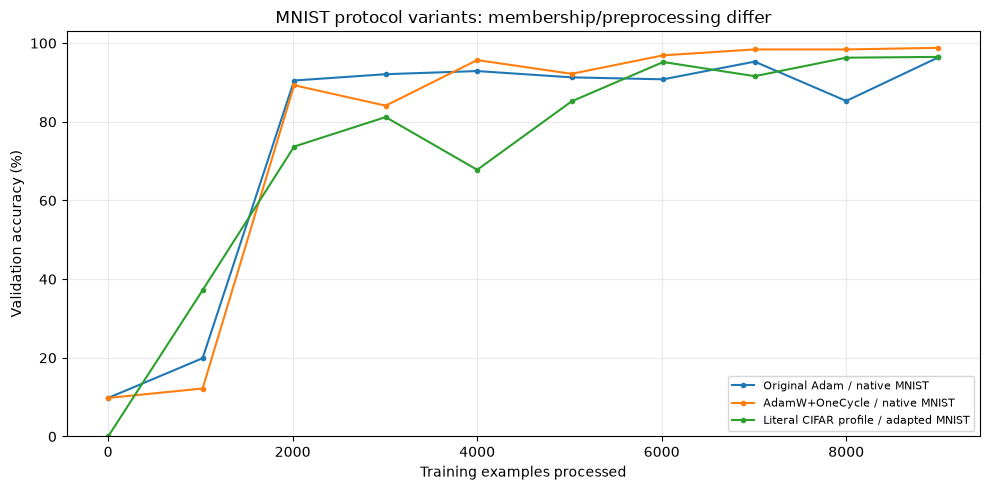

,Protocol,Final validation accuracy (%),Macro F1
0,Original Adam / native MNIST,96.4,0.9633
1,AdamW+OneCycle / native MNIST,98.8,0.9881
2,Literal CIFAR profile / adapted MNIST,96.5,0.9650


In [2]:
fig,ax=plt.subplots(figsize=(10,5))
summary=[]
for name,folder in [("Original Adam / native MNIST","mnist_9000_seed42"),
                    ("AdamW+OneCycle / native MNIST","mnist_nguyen_optimizer_seed42"),
                    ("Literal CIFAR profile / adapted MNIST","mnist_nguyen_literal_seed42")]:
    f=pd.read_csv(ROOT/"results"/folder/"results.csv")
    ax.plot(f.examples_processed,100*f.accuracy,marker=".",label=name)
    summary.append({"Protocol":name,"Final validation accuracy (%)":100*f.iloc[-1].accuracy,
                    "Macro F1":f.iloc[-1].f1})
ax.set(xlabel="Training examples processed",ylabel="Validation accuracy (%)",ylim=(0,103),
       title="MNIST protocol variants: membership/preprocessing differ")
ax.grid(alpha=.25);ax.legend(fontsize=8);fig.tight_layout();plt.show()
display(pd.DataFrame(summary).round(4))

## Checkpoint audit

The saved checkpoint was reloaded and evaluated on the exact validation rows, using deterministic eval preprocessing and no optimizer updates. The source membership matches configured loaders; all final metrics reproduce within 1e-12. The full 100x100 confusion matrix is archived in JSON; this figure aggregates outputs 10-99 into an Other column. Macro scores cover only the ten real labels, while outside-class predictions still count as accuracy errors and false negatives.

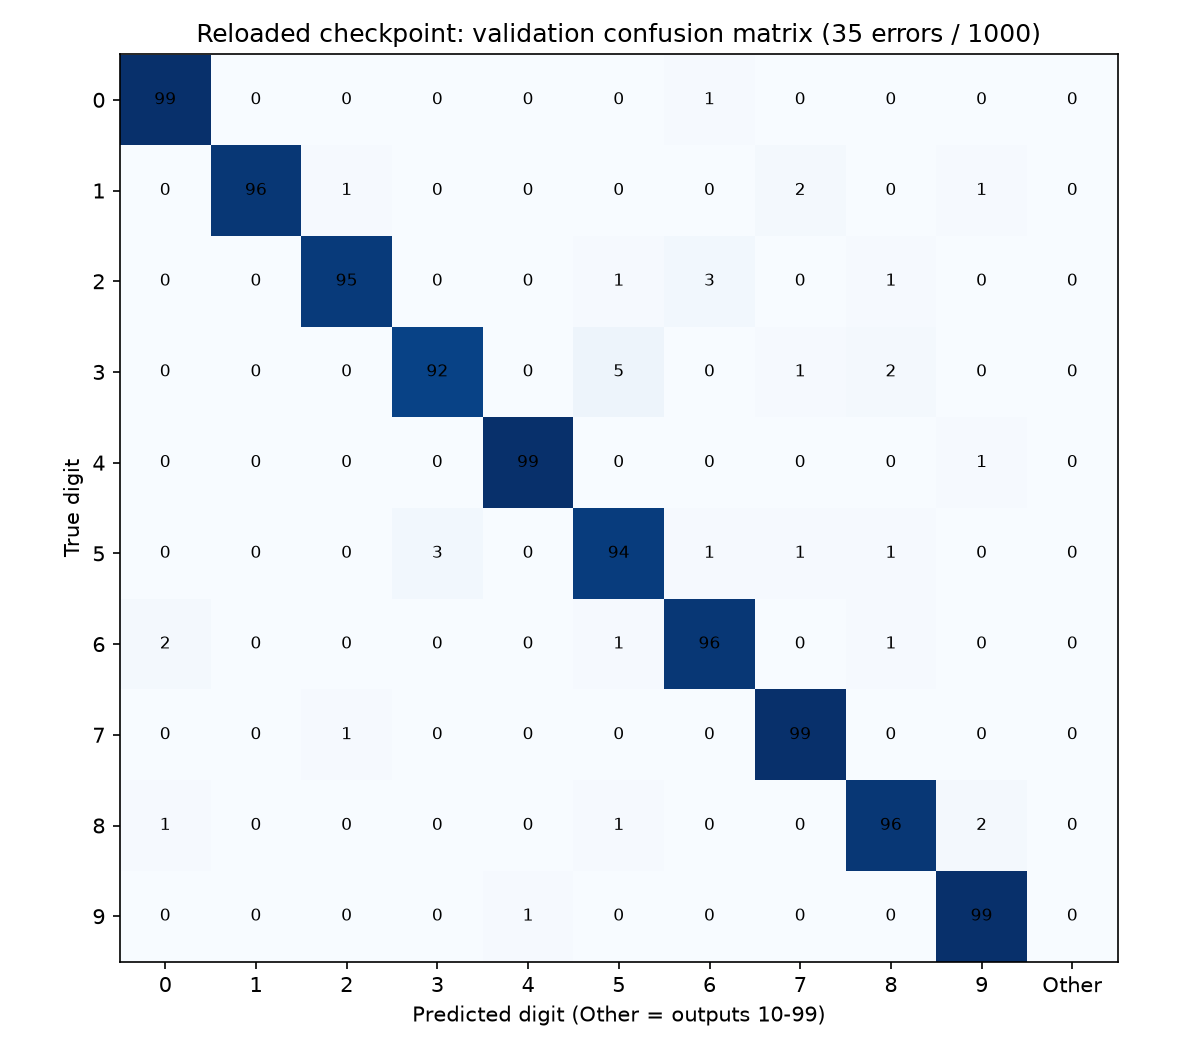

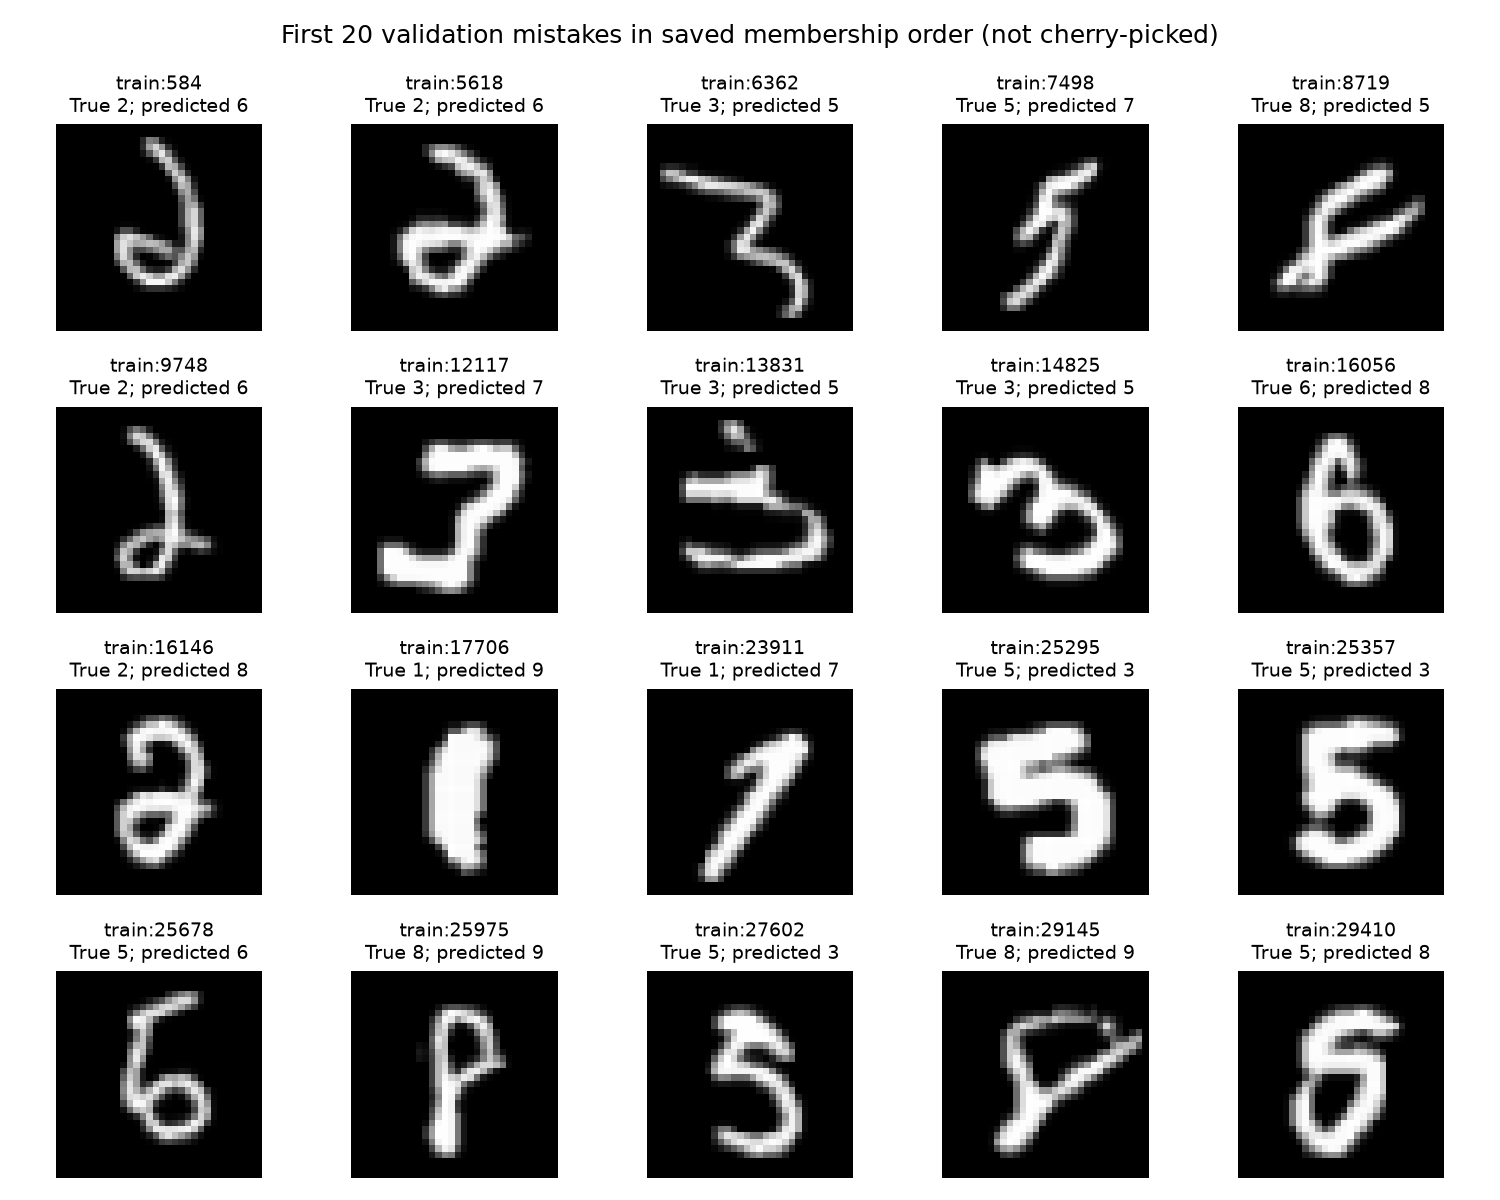

Checkpoint SHA-256: 8f4d2914688f4a0fa30e1bf3378c589134f74557eecc2c0df27e56dd3350c949


In [3]:
display(Image(filename=str(RUN/"audit/confusion_matrix.png")))
display(Image(filename=str(RUN/"audit/misclassified_examples.png")))
print("Checkpoint SHA-256:",audit["checkpoint_sha256"])

## CIFAR source mismatch: do not claim a verified matched-result comparison

Reference settings: `src/rawsgd-cifar-100.ipynb` at origin/main **3d356f9**, max LR 0.0005. The root-level notebook uses 0.002. The published `results/smallresnet-cifar-100.csv` reports 39.5% with 0.002; the supplied comparison screenshot reports 43.2% with 0.0005. The screenshot's source run record and CSV are needed before plotting it as a verified matched reference. These conflicting artifacts are not relabelled or combined.

The run also intentionally omits Nguyen's dummy train-mode shape forward, which can modify BatchNorm statistics. CPU fallback and package/hardware differences are recorded. Even literally matched hyperparameters do not make MNIST and CIFAR tasks equally difficult. One seed does not establish robustness or catastrophic-forgetting resistance.

## Reproduce

```powershell
python -m src.train_online --config configs/mnist_nguyen_literal.yaml --output data/processed/mnist_nguyen_literal_seed42
python -m src.audit_mnist --run data/processed/mnist_nguyen_literal_seed42 --output results/mnist_nguyen_literal_seed42/audit
```

Use new output folders when reproducing. Dataset images and weights remain local. Windows worker startup and CPU fallback can substantially affect wall time; do not compare it directly to Nguyen's CUDA timing. Training compute excludes loading/evaluation; run wall includes those during the timed run.
